In [113]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb

from sklearn.metrics import roc_auc_score

import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [47]:
df = pd.read_csv('./data/movie_blockbusters.csv')

## Data preparation and data cleaning

In [48]:
df.head()

,movie_id,title,year,decade,genre,runtime_min,budget_usd,revenue_usd,profit_usd,roi,rating,vote_count,popularity,blockbuster
0,1,Movie_0001,2020,2020s,Comedy,96,2.089233e+07,2.739209e+07,6.499763e+06,0.311,7.0,216326,9.64,0
1,2,Movie_0002,1981,1980s,Sci-Fi,128,3.063336e+08,1.237479e+09,9.311449e+08,3.040,5.3,49703,7.65,1
2,3,Movie_0003,1995,1990s,Horror,79,8.793950e+06,4.667246e+06,-4.126704e+06,-0.469,3.4,9476,16.68,0
3,4,Movie_0004,1988,1980s,Comedy,101,3.871710e+06,1.612737e+06,-2.258972e+06,-0.583,8.2,15698,2.93,0
4,5,Movie_0005,2023,2020s,Documentary,75,1.283539e+06,5.743469e+05,-7.091917e+05,-0.553,4.3,38698,9.10,0


In [49]:
df.describe()

,movie_id,year,runtime_min,budget_usd,revenue_usd,profit_usd,roi,rating,vote_count,popularity,blockbuster
count,5000.000000,5000.000000,5000.000000,5.000000e+03,5.000000e+03,5.000000e+03,5000.000000,5000.000000,5.000000e+03,5000.000000,5000.00000
mean,2500.500000,2002.200600,109.358000,4.320764e+07,1.311844e+08,8.797676e+07,1.517586,5.997220,6.932152e+04,20.002864,0.13460
std,1443.520003,12.956324,22.217699,9.897210e+07,5.012581e+08,4.485541e+08,3.233827,1.494474,3.210306e+05,26.695885,0.34133
min,1.000000,1980.000000,60.000000,1.054897e+05,1.403244e+04,-8.009002e+08,-0.980000,1.000000,8.700000e+01,0.370000,0.00000
25%,1250.750000,1991.000000,93.000000,5.072756e+06,5.707047e+06,-1.252205e+06,-0.258000,5.000000,7.866750e+03,6.330000,0.00000
50%,2500.500000,2002.000000,109.000000,1.501351e+07,2.327998e+07,5.049109e+06,0.506500,6.000000,2.181550e+04,12.195000,0.00000
75%,3750.250000,2013.000000,126.000000,4.191808e+07,8.887134e+07,4.406719e+07,2.029000,7.000000,5.766675e+04,23.585000,0.00000
max,5000.000000,2024.000000,185.000000,2.369801e+09,1.495518e+10,1.455845e+10,43.322000,10.000000,1.823086e+07,627.870000,1.00000


In [50]:
df.isnull().sum()

movie_id       0
title          0
year           0
decade         0
genre          0
runtime_min    0
budget_usd     0
revenue_usd    0
profit_usd     0
roi            0
rating         0
vote_count     0
popularity     0
blockbuster    0
dtype: int64

In [51]:
df = df.drop_duplicates()

In [52]:
df.decade = df.decade.str.removesuffix('s').astype(int)

In [53]:
df.dtypes

movie_id         int64
title              str
year             int64
decade           int64
genre              str
runtime_min      int64
budget_usd     float64
revenue_usd    float64
profit_usd     float64
roi            float64
rating         float64
vote_count       int64
popularity     float64
blockbuster      int64
dtype: object

In [54]:
# Remove post-release metrics

del df['movie_id']
del df['title']
del df['revenue_usd']
del df['profit_usd']
del df['roi']
del df['rating']
del df['vote_count']
del df['popularity']

In [55]:
df.head()

,year,decade,genre,runtime_min,budget_usd,blockbuster
0,2020,2020,Comedy,96,2.089233e+07,0
1,1981,1980,Sci-Fi,128,3.063336e+08,1
2,1995,1990,Horror,79,8.793950e+06,0
3,1988,1980,Comedy,101,3.871710e+06,0
4,2023,2020,Documentary,75,1.283539e+06,0


## Dataset Partitioning

In [56]:
df_full_train, df_test = train_test_split(df, test_size=0.2, stratify=df.blockbuster)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, stratify=df_full_train.blockbuster)

df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_full_train = df_full_train.blockbuster.values
y_train = df_train.blockbuster.values
y_val = df_val.blockbuster.values
y_test = df_test.blockbuster.values

del df_full_train['blockbuster']
del df_train['blockbuster']
del df_val['blockbuster']
del df_test['blockbuster']

## EDA

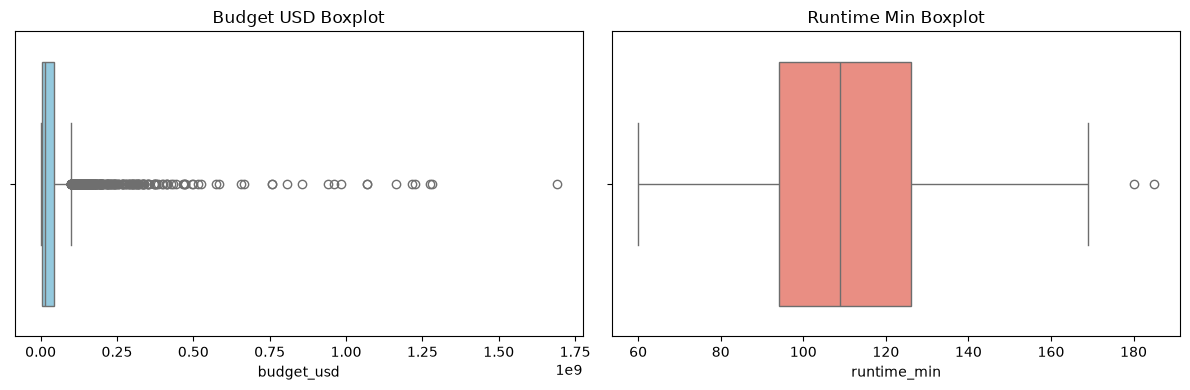

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df_train['budget_usd'], ax=axes[0], color='skyblue').set_title('Budget USD Boxplot')
sns.boxplot(x=df_train['runtime_min'], ax=axes[1], color='salmon').set_title('Runtime Min Boxplot')
plt.tight_layout()

<Axes: xlabel='budget_usd', ylabel='Count'>

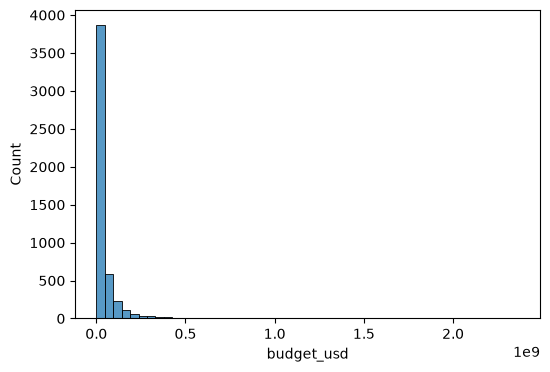

In [75]:
fig, axes = plt.subplots(1, 1, figsize=(6, 4))
sns.histplot(df.budget_usd, bins=50)

In [58]:
def prepare_features(df_input):
    df_out = df_input.copy()
    
    # 1. Log-transform skewed budget
    df_out['log_budget'] = np.log1p(df_out['budget_usd'])
    
    # 2. Financial intensity ratio (budget per minute)
    df_out['budget_per_min'] = df_out['budget_usd'] / df_out['runtime_min']
    
    return df_out

df_train_fe = prepare_features(df_train)
df_val_fe = prepare_features(df_val)

In [59]:
df_train_fe.head()

,year,decade,genre,runtime_min,budget_usd,log_budget,budget_per_min
0,2016,2010,Animation,97,2.266216e+07,16.936207,233630.557320
1,1992,1990,Animation,85,2.291187e+07,16.947166,269551.439529
2,2015,2010,Thriller,101,8.007651e+06,15.895908,79283.668812
3,2014,2010,Action,125,1.208205e+08,18.609817,966564.105200
4,2009,2000,Adventure,134,3.915682e+07,17.483085,292215.098507


In [60]:
# Categorical Encoding

train_dicts = df_train_fe.to_dict(orient='records')
val_dicts = df_val_fe.to_dict(orient='records')

dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

In [61]:
# Feature Scaling

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

In [62]:
df.blockbuster.value_counts(normalize=True)

blockbuster
0    0.8654
1    0.1346
Name: proportion, dtype: float64

## Model Selection

1. LogisticRegression

In [65]:
lr = LogisticRegression(class_weight='balanced', max_iter=1000)
lr.fit(X_train_scaled, y_train)

y_pred_val_lr = lr.predict_proba(X_val_scaled)[:, 1]
auc_lr = roc_auc_score(y_val, y_pred_val_lr)

auc_lr

0.8406336972810962

2. Decision Tree

In [ ]:
scores = []

for depth in [3, 5, 7, 10]:
    for leaf in [1, 5, 10, 20]:
        dt = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, class_weight='balanced')
        dt.fit(X_train, y_train)
        y_pred = dt.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((depth, leaf, auc))

        print(f"DecisionTree (depth={depth}, leaf={leaf}) -> Val ROC-AUC: {auc:.4f}")

DecisionTree (depth=3, leaf=1) -> Val ROC-AUC: 0.7872
DecisionTree (depth=3, leaf=5) -> Val ROC-AUC: 0.7872
DecisionTree (depth=3, leaf=10) -> Val ROC-AUC: 0.7872
DecisionTree (depth=3, leaf=20) -> Val ROC-AUC: 0.7872
DecisionTree (depth=5, leaf=1) -> Val ROC-AUC: 0.8048
DecisionTree (depth=5, leaf=5) -> Val ROC-AUC: 0.7989
DecisionTree (depth=5, leaf=10) -> Val ROC-AUC: 0.7966
DecisionTree (depth=5, leaf=20) -> Val ROC-AUC: 0.8058
DecisionTree (depth=7, leaf=1) -> Val ROC-AUC: 0.7898
DecisionTree (depth=7, leaf=5) -> Val ROC-AUC: 0.7927
DecisionTree (depth=7, leaf=10) -> Val ROC-AUC: 0.8026
DecisionTree (depth=7, leaf=20) -> Val ROC-AUC: 0.8053
DecisionTree (depth=10, leaf=1) -> Val ROC-AUC: 0.7852
DecisionTree (depth=10, leaf=5) -> Val ROC-AUC: 0.7818
DecisionTree (depth=10, leaf=10) -> Val ROC-AUC: 0.7670
DecisionTree (depth=10, leaf=20) -> Val ROC-AUC: 0.7719


In [82]:
columns = ['max_depth', 'min_samples_leaf', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores_pivot = df_scores.pivot(index='min_samples_leaf', columns=['max_depth'], values=['auc'])
df_scores_pivot.round(3)

auc                     
max_depth            3      5      7      10
min_samples_leaf                            
1                 0.787  0.805  0.790  0.785
5                 0.787  0.799  0.793  0.782
10                0.787  0.797  0.803  0.767
20                0.787  0.806  0.805  0.772

<Axes: xlabel='None-max_depth', ylabel='min_samples_leaf'>

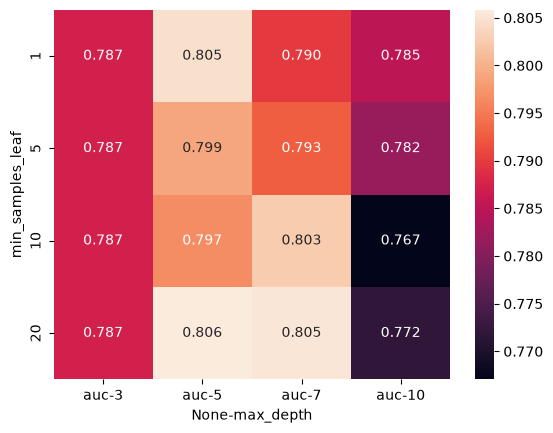

In [83]:
sns.heatmap(df_scores_pivot, annot=True, fmt=".3f")

In [84]:
dt = DecisionTreeClassifier(max_depth=5, min_samples_leaf=1, class_weight='balanced')
dt.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even 

3. Random Forest

In [88]:
scores = []

for n in range(10, 201, 10):
    rf = RandomForestClassifier(n_estimators=n, class_weight='balanced', n_jobs=-1)
    rf.fit(X_train, y_train)

    y_pred_val_rf = rf.predict_proba(X_val)[:, 1]
    auc_rf = roc_auc_score(y_val, y_pred_val_rf)
    
    scores.append((n, auc_rf))

In [89]:
df_scores = pd.DataFrame(scores, columns=['n_estimators', 'auc'])
df_scores

,n_estimators,auc
0,10,0.813016
1,20,0.816108
2,30,0.814207
3,40,0.816142
4,50,0.816669
5,60,0.816206
6,70,0.816549
7,80,0.818369
8,90,0.821023
9,100,0.818077


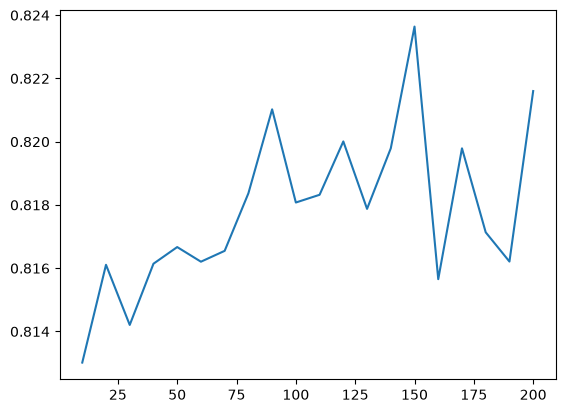

In [90]:
plt.plot(df_scores.n_estimators, df_scores.auc)

In [92]:
# best_n = 150

In [93]:
scores = []

for depth in [5, 10, 15]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n, max_depth=depth, class_weight='balanced', n_jobs=-1)
        rf.fit(X_train, y_train)

        y_pred_val_rf = rf.predict_proba(X_val)[:, 1]
        auc_rf = roc_auc_score(y_val, y_pred_val_rf)

        scores.append((depth, n, auc_rf))

In [94]:
columns = ['max_depth', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

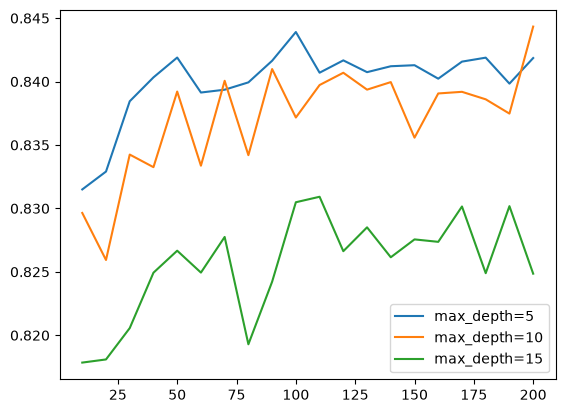

In [95]:
for d in [5, 10, 15]:
    df_subset = df_scores[df_scores.max_depth == d]
    
    plt.plot(df_subset.n_estimators, df_subset.auc, label='max_depth=%d' % d)

plt.legend()

In [101]:
best_max_depth = 5

In [102]:
scores = []

for s in [1, 3, 5, 10, 50]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n, max_depth=best_max_depth, min_samples_leaf=s, class_weight='balanced', n_jobs=-1)
        rf.fit(X_train, y_train)

        y_pred_val_rf = rf.predict_proba(X_val)[:, 1]
        auc_rf = roc_auc_score(y_val, y_pred_val_rf)

        scores.append((s, n, auc_rf))

In [103]:
columns = ['min_samples_leaf', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

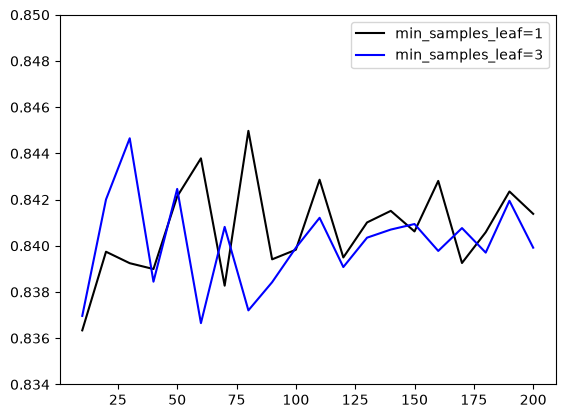

In [109]:
colors = ['black', 'blue', 'orange', 'red', 'grey']
# values = [1, 3, 5, 10, 50]    Removed 50
# values = [1, 3, 5, 10]
values = [1, 3]

for s, col in zip(values, colors):
    df_subset = df_scores[df_scores.min_samples_leaf == s]
    
    plt.plot(df_subset.n_estimators, df_subset.auc, color=col, label='min_samples_leaf=%d' % s)

plt.ylim(0.834,0.85)
plt.legend()

In [165]:
# best_min_samples_leaf = 1

In [ ]:
rf = RandomForestClassifier(n_estimators=106, max_depth=5, min_samples_leaf=1, class_weight='balanced', n_jobs=-1)
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",106
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` chan

4. XGBoost

In [114]:
features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)

In [121]:
def parse_xgb_output(output):
    results = []

    for line in output.stdout.strip().split('\n'):
        it_line, train_line, val_line = line.split('\t')

        it = int(it_line.strip('[]'))
        train = float(train_line.split(':')[1])
        val = float(val_line.split(':')[1])

        results.append((it, train, val))
    
    columns = ['num_iter', 'train_auc', 'val_auc']
    df_results = pd.DataFrame(results, columns=columns)
    return df_results

In [119]:
scores = {}

In [138]:
%%capture output

scale_pos_weight = (len(y_train) - sum(y_train)) / sum(y_train)

xgb_params = {
    'eta': 1,
    'max_depth': 6,
    'min_child_weight': 1,
    'gamma': 1.0,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'scale_pos_weight': scale_pos_weight,

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

watchlist = [(dtrain, 'train'), (dval, 'val')]

model = xgb.train(xgb_params, dtrain, num_boost_round=200, evals=watchlist, verbose_eval=5)

In [ ]:
key = 'eta=%s' % (xgb_params['eta'])
scores[key] = parse_xgb_output(output)
key

'eta=1'

In [140]:
scores.keys()

dict_keys(['eta=0.01', 'eta=0.05', 'eta=0.1', 'eta=0.3', 'eta=1'])

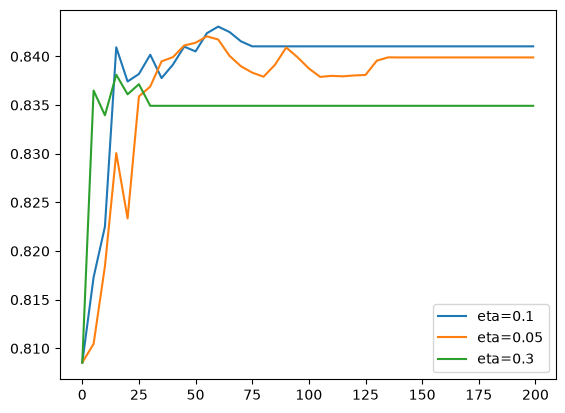

In [145]:
etas = ['eta=0.1', 'eta=0.05', 'eta=0.3']

for eta in etas:
    df_score = scores[eta]
    plt.plot(df_score.num_iter, df_score.val_auc, label=eta)
plt.legend()

In [146]:
best_eta = 0.1

In [150]:
scores = {}

In [160]:
%%capture output

scale_pos_weight = (len(y_train) - sum(y_train)) / sum(y_train)

xgb_params = {
    'eta': best_eta,
    'max_depth': 10,
    'min_child_weight': 1,
    'gamma': 1.0,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'scale_pos_weight': scale_pos_weight,

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

watchlist = [(dtrain, 'train'), (dval, 'val')]

model = xgb.train(xgb_params, dtrain, num_boost_round=200, evals=watchlist, verbose_eval=5)

In [179]:
key = 'max_depth=%s' % (xgb_params['max_depth'])
scores[key] = parse_xgb_output(output)
key

'max_depth=3'

In [162]:
scores.keys()

dict_keys(['max_depth=3', 'max_depth=4', 'max_depth=6', 'max_depth=10'])

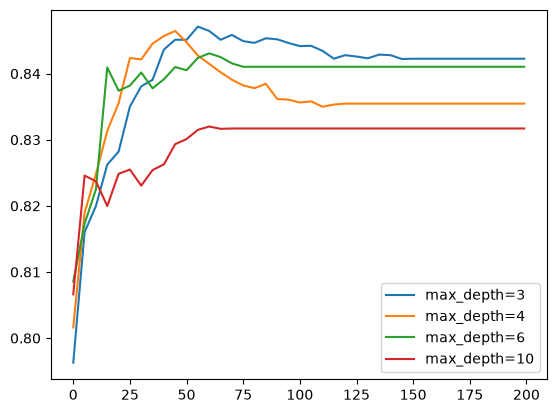

In [163]:
for max_depth, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=max_depth)

plt.legend()

In [166]:
best_max_depth = 3

In [167]:
scores = {}

In [174]:
%%capture output

scale_pos_weight = (len(y_train) - sum(y_train)) / sum(y_train)

xgb_params = {
    'eta': best_eta,
    'max_depth': best_max_depth,
    'min_child_weight': 30,
    'gamma': 1.0,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'scale_pos_weight': scale_pos_weight,

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

watchlist = [(dtrain, 'train'), (dval, 'val')]

model = xgb.train(xgb_params, dtrain, num_boost_round=200, evals=watchlist, verbose_eval=5)

In [175]:
key = 'min_child_weight=%s' % (xgb_params['min_child_weight'])
scores[key] = parse_xgb_output(output)
key

'min_child_weight=30'

In [176]:
scores.keys()

dict_keys(['min_child_weight=1', 'min_child_weight=10', 'min_child_weight=30'])

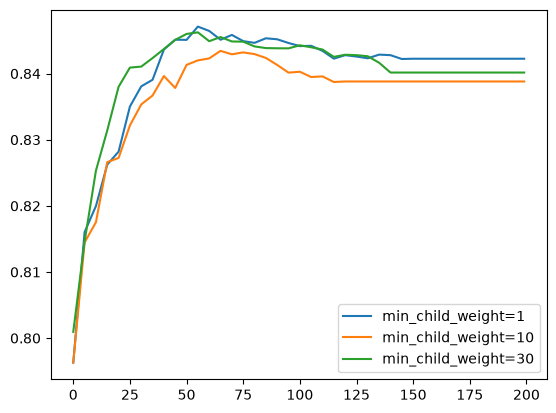

In [178]:
for min_child_weight, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=min_child_weight)

plt.legend()

In [180]:
best_min_child_weight = 1

In [182]:
scores = {}

In [200]:
%%capture output

scale_pos_weight = (len(y_train) - sum(y_train)) / sum(y_train)

xgb_params = {
    'eta': best_eta,
    'max_depth': best_max_depth,
    'min_child_weight': best_min_child_weight,
    'gamma': 6.0,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'scale_pos_weight': scale_pos_weight,

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

watchlist = [(dtrain, 'train'), (dval, 'val')]

model = xgb.train(xgb_params, dtrain, num_boost_round=200, evals=watchlist, verbose_eval=5)

In [201]:
key = 'gamma=%s' % (xgb_params['gamma'])
scores[key] = parse_xgb_output(output)
key

'gamma=6.0'

In [202]:
scores.keys()

dict_keys(['gamma=0', 'gamma=1.0', 'gamma=3.0', 'gamma=5.0', 'gamma=10.0', 'gamma=7.0', 'gamma=6.0'])

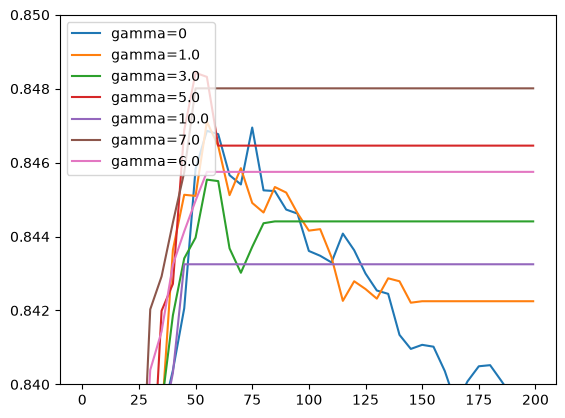

In [204]:
for gamma, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=gamma)

plt.ylim(0.84, 0.85)
plt.legend()

In [205]:
best_gamma = 7

In [210]:
scale_pos_weight = (len(y_train) - sum(y_train)) / sum(y_train)

xgb_params = {
    'eta': 0.1,
    'max_depth': 3,
    'min_child_weight': 1,
    'gamma': 7.0,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'scale_pos_weight': scale_pos_weight,

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=175)

### Selecting the final model

In [221]:
lr = LogisticRegression(class_weight='balanced', max_iter=1000)
lr.fit(X_train_scaled, y_train)

y_pred_val_lr = lr.predict_proba(X_val_scaled)[:, 1]
auc_lr = roc_auc_score(y_val, y_pred_val_lr)

auc_lr

0.8406336972810962

In [215]:
dt = DecisionTreeClassifier(max_depth=5, min_samples_leaf=1, class_weight='balanced')
dt.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even 

In [222]:
y_pred = dt.predict_proba(X_val)[:, 1]
auc_dt = roc_auc_score(y_val, y_pred)

auc_dt

0.8047570113466067

In [ ]:
rf = RandomForestClassifier(n_estimators=106, max_depth=5, min_samples_leaf=1, class_weight='balanced', n_jobs=-1)
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",106
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` chan

In [223]:
y_pred = rf.predict_proba(X_val)[:, 1]
auc_rf = roc_auc_score(y_val, y_pred)

auc_rf

0.8398587026332692

In [219]:
scale_pos_weight = (len(y_train) - sum(y_train)) / sum(y_train)

xgb_params = {
    'eta': 0.1,
    'max_depth': 3,
    'min_child_weight': 1,
    'gamma': 7.0,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'scale_pos_weight': scale_pos_weight,

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=175)

In [224]:
y_pred = model.predict(dval)
auc_xgb = roc_auc_score(y_val, y_pred)

auc_xgb

0.8480068507814172

In [236]:
d = dict(zip(['auc_lr', 'auc_dt', 'auc_rf', 'auc_xgb'],[auc_lr, auc_dt, auc_rf, auc_xgb]))

for k, v in d.items():
    print(f'{k} -> {v}')

max_key = max(d, key=d.get)
max_value = d[max_key]

print(f'\nMaximum: {max_key} -> {max_value}')


auc_lr -> 0.8406336972810962
auc_dt -> 0.8047570113466067
auc_rf -> 0.8398587026332692
auc_xgb -> 0.8480068507814172

Maximum: auc_xgb -> 0.8480068507814172


## Final Training

In [237]:
df_full_train_fe = prepare_features(df_full_train)
df_test_fe = prepare_features(df_test)

In [238]:
full_train_dicts = df_full_train_fe.to_dict(orient='records')
test_dicts = df_test_fe.to_dict(orient='records')

dv_final = DictVectorizer(sparse=False)
X_full_train = dv_final.fit_transform(full_train_dicts)
X_test = dv_final.transform(test_dicts)

In [239]:
features = list(dv.get_feature_names_out())
d_full_train = xgb.DMatrix(X_full_train, label=y_full_train, feature_names=features)
d_test = xgb.DMatrix(X_test, label=y_test, feature_names=features)

In [240]:
scale_pos_weight = (len(y_full_train) - sum(y_full_train)) / sum(y_full_train)

xgb_params = {
    'eta': 0.1,
    'max_depth': 3,
    'min_child_weight': 1,
    'gamma': 7.0,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'scale_pos_weight': scale_pos_weight,

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, d_full_train, num_boost_round=175)

In [241]:
y_pred = model.predict(d_test)
auc = roc_auc_score(y_test, y_pred)

auc

0.8383344037679298